# 136 · A mini-Dreamer world model (RSSM) from pixels: watch it imagine, and find where imagination drifts

In [1]:
import os, time, numpy as np, torch, torch.nn as nn, torch.nn.functional as F, matplotlib.pyplot as plt, mujoco
from vlacourse.rl_envs import PendulumEnv

device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cuda":
    torch.cuda.set_per_process_memory_fraction(0.8)
IMG, T_SEQ, DETER, STOCH = 64, 32, 200, 30

def collect(n_eps, seed=0):
    env, rng, obs_all, act_all, rew_all = PendulumEnv(max_steps=100), np.random.default_rng(seed), [], [], []
    cam = mujoco.MjvCamera(); cam.lookat[:] = [0, 0, 1.5]; cam.distance, cam.azimuth, cam.elevation = 3.2, 90, 0
    for e in range(n_eps):
        env.reset(seed=seed + e); O, A, R = [], [], []; done = False; a = 0.0
        while not done:
            O.append(env.render(size=(IMG, IMG), camera=cam))
            a = float(np.clip(0.8 * a + rng.normal(0, 0.6), -1, 1))
            _, r, te, tr, _ = env.step([a]); A.append([a]); R.append(r); done = te or tr
        obs_all.append(np.array(O)); act_all.append(np.array(A, np.float32)); rew_all.append(np.array(R, np.float32))
    return obs_all, act_all, rew_all

class RSSM(nn.Module):
    def __init__(self, act_dim=1):
        super().__init__()
        self.enc = nn.Sequential(nn.Conv2d(3, 32, 4, 2), nn.SiLU(), nn.Conv2d(32, 64, 4, 2), nn.SiLU(), nn.Conv2d(64, 128, 4, 2), nn.SiLU(), nn.Conv2d(128, 256, 4, 2), nn.SiLU(), nn.Flatten())
        self.gru = nn.GRUCell(STOCH + act_dim, DETER)
        self.prior = nn.Sequential(nn.Linear(DETER, 200), nn.SiLU(), nn.Linear(200, 2 * STOCH))
        self.post = nn.Sequential(nn.Linear(DETER + 1024, 200), nn.SiLU(), nn.Linear(200, 2 * STOCH))
        self.dec_in = nn.Linear(DETER + STOCH, 1024)
        self.dec = nn.Sequential(nn.ConvTranspose2d(1024, 128, 5, 2), nn.SiLU(), nn.ConvTranspose2d(128, 64, 5, 2), nn.SiLU(), nn.ConvTranspose2d(64, 32, 6, 2), nn.SiLU(), nn.ConvTranspose2d(32, 3, 6, 2))
        self.reward = nn.Sequential(nn.Linear(DETER + STOCH, 200), nn.SiLU(), nn.Linear(200, 1))

    @staticmethod
    def dist(x):
        mu, s = x.chunk(2, -1)
        return torch.distributions.Normal(mu, F.softplus(s) + 0.1)

    def decode(self, h, z):
        return self.dec(self.dec_in(torch.cat([h, z], -1))[..., None, None])

    def observe(self, obs, act):
        B, T = act.shape[:2]
        emb = self.enc(obs.flatten(0, 1)).view(B, T, -1)
        h, z = torch.zeros(B, DETER, device=obs.device), torch.zeros(B, STOCH, device=obs.device)
        hs, zs, kls = [], [], []
        for t in range(T):
            h = self.gru(torch.cat([z, act[:, t - 1] if t else torch.zeros_like(act[:, 0])], -1), h)
            prior, post = self.dist(self.prior(h)), self.dist(self.post(torch.cat([h, emb[:, t]], -1)))
            z = post.rsample(); hs.append(h); zs.append(z)
            kls.append(torch.distributions.kl_divergence(post, prior).sum(-1).clamp(min=1.0))
        return torch.stack(hs, 1), torch.stack(zs, 1), torch.stack(kls, 1)

    def imagine(self, h, z, actions):
        out = []
        for a in actions.unbind(1):
            h = self.gru(torch.cat([z, a], -1), h); z = self.dist(self.prior(h)).sample(); out.append((h, z))
        return out

def to_tensor(frames):
    return torch.tensor(frames, dtype=torch.float32, device=device).permute(0, 1, 4, 2, 3) / 255.0 - 0.5

In [2]:
t0 = time.time()
obs, act, rew = collect(150)
test_obs, test_act, _ = collect(10, seed=999)
print(f"collected {sum(len(o) for o in obs)} frames in {time.time() - t0:.0f}s")

collected 15000 frames in 58s


In [3]:
model = RSSM().to(device); opt = torch.optim.Adam(model.parameters(), 3e-4)
rng, t0, log = np.random.default_rng(0), time.time(), []
for step in range(4000):
    idx = rng.integers(0, len(obs), 16); st = [rng.integers(0, len(obs[i]) - T_SEQ) for i in idx]
    o = to_tensor(np.stack([obs[i][s:s + T_SEQ] for i, s in zip(idx, st)]))
    a = torch.tensor(np.stack([act[i][s:s + T_SEQ] for i, s in zip(idx, st)]), device=device)
    r = torch.tensor(np.stack([rew[i][s:s + T_SEQ] for i, s in zip(idx, st)]), device=device)
    h, z, kl = model.observe(o, a)
    rec = model.decode(h.flatten(0, 1), z.flatten(0, 1)).view_as(o)
    loss = F.mse_loss(rec, o, reduction="none").sum((2, 3, 4)).mean() + F.mse_loss(model.reward(torch.cat([h, z], -1))[..., 0], r) * 10 + kl.mean()
    opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 100); opt.step()
    if step % 500 == 0:
        log.append(loss.item()); print(f"step {step} loss {loss.item():.1f} ({time.time() - t0:.0f}s)")

step 0 loss 3735.8 (1s)


step 500 loss 25.0 (252s)


step 1000 loss 14.2 (506s)


step 1500 loss 12.3 (762s)


step 2000 loss 7.7 (955s)


step 2500 loss 7.5 (1118s)


step 3000 loss 8.4 (1184s)


step 3500 loss 5.4 (1237s)


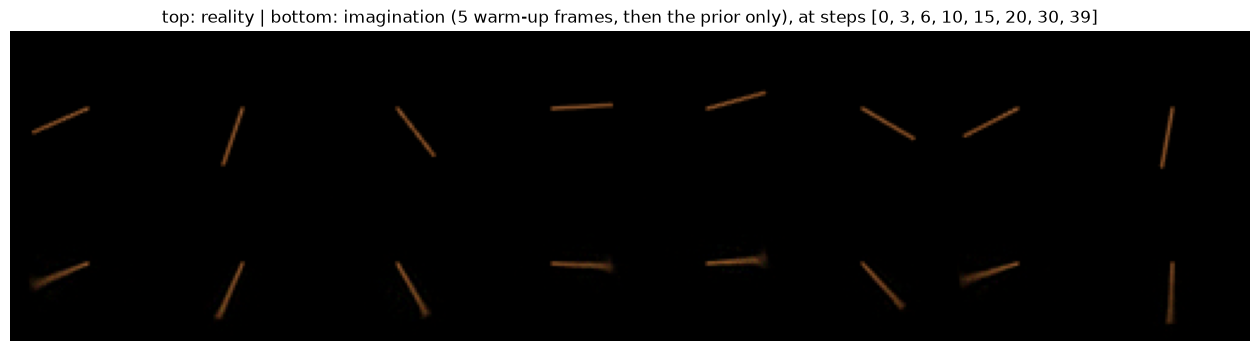

In [4]:
@torch.no_grad()
def imagine_episode(i, warmup=5, horizon=40):
    o = to_tensor(test_obs[i][None, :warmup]); a = torch.tensor(test_act[i][None], device=device)
    h, z, _ = model.observe(o, a[:, :warmup])
    imag = model.imagine(h[:, -1], z[:, -1], a[:, warmup - 1: warmup - 1 + horizon])
    pred = torch.stack([model.decode(hh, zz) for hh, zz in imag], 1)[0]
    return ((pred.permute(0, 2, 3, 1).cpu().numpy() + 0.5).clip(0, 1) * 255).astype(np.uint8), test_obs[i][warmup: warmup + horizon]

pred, real = imagine_episode(0)
idx = [0, 3, 6, 10, 15, 20, 30, 39]
plt.figure(figsize=(16, 4.2)); plt.imshow(np.vstack([np.hstack([real[k] for k in idx]), np.hstack([pred[k] for k in idx])])); plt.axis("off")
plt.title("top: reality | bottom: imagination (5 warm-up frames, then the prior only), at steps " + str(idx)); plt.show()

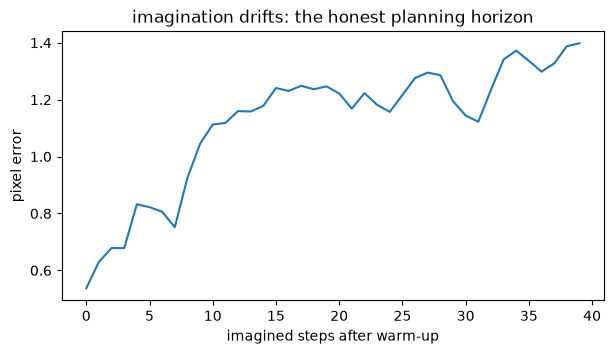

first step where error exceeds twice its initial value: 15


In [5]:
errs = np.mean([np.abs(p.astype(float) - r.astype(float)).mean((1, 2, 3)) for p, r in [imagine_episode(i) for i in range(10)]], 0)
plt.figure(figsize=(7, 3.5)); plt.plot(errs); plt.xlabel("imagined steps after warm-up"); plt.ylabel("pixel error"); plt.title("imagination drifts: the honest planning horizon"); plt.show()
print("first step where error exceeds twice its initial value:", int(np.argmax(errs > 2 * errs[:3].mean())))

### Watch the dream
Left: what really happened. Right: what the world model imagines after seeing only 5 frames (then no more observations).

In [6]:
from vlacourse import showcase as sc
pred, real = imagine_episode(1)
sc.side_by_side([list(real), list(pred)], ["reality", "imagination (prior only)"], title="136 reality vs imagination", fps=8, scale=4,
                footer="the dream starts sharp and drifts")

[array([[[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],
 
        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],
 
        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],
 
        ...,
 
        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],
 
        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],
 
        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]]], shape=(256, 512, 3), dtype=uint8),
 array([[[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [1, 1, 1],
         [1, 1, 1],
         [1, 1,